# M1-B2 — Classer les avis par motif d'insatisfaction

**Mode d'emploi.** Exécute les cellules dans l'ordre. Les `___` sont à compléter. Après chaque étape, le bloc
✅ indique le résultat que tu dois obtenir (à quelques centièmes près) : s'il est très différent, relis l'étape
avant d'avancer. Les cellules sans `___` sont fournies : lis-les, elles font partie de l'apprentissage.

In [25]:
import os
os.environ["KERAS_BACKEND"] = "torch"   # avant tout « import keras » : Keras utilisera PyTorch

import json
import time
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
CACHE = DATA / "cache"
CACHE.mkdir(exist_ok=True)
MODELS = ROOT / "models"

MODEL_NAME = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"

## Étape 1 — Démarrer

Cette cellule télécharge le modèle d'embeddings au premier lancement (environ 470 Mo, quelques minutes) :
lance-la tout de suite, et continue à lire pendant ce temps.

In [26]:
#It maps sentences & paragraphs to a 384 dimensional dense vector space and can be used for tasks like clustering or semantic search.
from sentence_transformers import SentenceTransformer

encoder = SentenceTransformer(MODEL_NAME)
encoder.encode(["Le lit était très inconfortable.", "Le matelas était défoncé."]).shape

(2, 384)

✅ `(2, 384)` : deux phrases, 384 nombres chacune.

In [27]:
# nmr : embeddings and similarity calculation for the given sentences
embedings = encoder.encode(["Le lit était très inconfortable.", "Le matelas était défoncé."])
print(embedings)
print("--------------------------\n")
similarities = encoder.similarity(embedings, embedings)
print(similarities.shape)

[[ 7.00614899e-02 -7.50993639e-02 -1.11025706e-01  4.28151041e-01
   4.18772072e-01  1.34459555e-01 -9.18732956e-02  1.28750801e-01
   2.04140827e-01  1.40361711e-01 -1.73149765e-01  3.63200903e-01
   3.42908174e-01  6.97743446e-02 -6.66006375e-03 -1.89588040e-01
  -1.41160324e-01 -5.28003395e-01 -8.29127654e-02  5.95887780e-01
   2.74283700e-02  2.02082008e-01  5.47954679e-01 -4.95108426e-01
  -2.20117018e-01 -2.21729368e-01  4.26969945e-01 -1.70982778e-01
  -2.32854053e-01 -4.24582869e-01 -2.52149910e-01 -2.66319871e-01
  -5.69320917e-02  4.94851917e-03  1.98848531e-01 -2.21159622e-01
  -5.45828119e-02  4.07343566e-01 -5.92232719e-02 -2.02607363e-01
   1.55042022e-01  1.25261486e-01  1.47444140e-02 -1.84722364e-01
   5.09894788e-01  1.69401944e-01  9.31475461e-02 -3.19055349e-01
   4.41051871e-01  8.18377584e-02  8.62842277e-02  1.33056372e-01
  -8.52901638e-02 -3.99914056e-01 -5.35266757e-01 -1.12133697e-01
   1.28839135e-01 -3.36254165e-02 -3.16987306e-01  6.92090392e-01
  -3.12766

## Étape 2 — Explorer le corpus

- `avis_motifs.csv` : 1 200 avis de 2016, étiquetés par un LLM → pour **entraîner et tester**.
- `avis_recents.csv` : 180 avis de 2017, étiquetés à la main → **uniquement pour évaluer**, à la fin.

In [28]:
avis = pd.read_csv(DATA / "avis_motifs.csv")
recents = pd.read_csv(DATA / "avis_recents.csv")
print(len(avis), "avis,", len(recents), "avis récents")
avis["motif"].value_counts()

1200 avis, 180 avis récents


motif
proprete        189
bruit           184
equipements     144
chambre         139
restauration    138
accueil         138
reservation     112
prix             89
emplacement      67
Name: count, dtype: int64

✅ 9 motifs, de `proprete` (189 avis) à `emplacement` (67). Les classes sont **déséquilibrées** : c'est pourquoi on mesurera le F1 **macro** (chaque motif compte autant).

In [29]:
# *description du verbatim table 'avis' 2016, étiquetés par un LLM → pour **entraîner et tester**.
avis["texte"].str.len().describe().round()

count    1200.0
mean      170.0
std        64.0
min        28.0
25%       120.0
50%       167.0
75%       214.0
max       413.0
Name: texte, dtype: float64

In [30]:
# Echantillon
pd.set_option("display.max_colwidth", 200)
avis.sample(20, random_state=0)[["avis_id", "texte", "motif"]]

,avis_id,texte,motif
198,199,"Nous venons souvent, mais cette fois non. Impossible de dormir à cause du bruit de la rue.",bruit
328,329,Le veilleur de nuit dormait à la réception et ne répondait pas. On nous a répondu sèchement quand nous avons signalé un problème.,accueil
45,46,Les portes claquent dans le couloir toute la nuit. On entendait la tuyauterie à chaque fois qu'un voisin tirait la chasse. On attendait mieux.,bruit
263,264,"Vacances en famille, une semaine. Tout est payant : la serviette de piscine, le transat, le coffre.",prix
621,622,"Séjour professionnel de trois nuits. Les femmes de chambre parlaient fort dans le couloir dès 8 h. La climatisation faisait un bruit d'avion toute la nuit. Les murs sont en papier, on entend tout ...",bruit
520,521,"petit-dejeuner tres decevant : pain industriel et cafe tiede. soiree au bar de l'hotel jusqu'a 2 h, la musique resonnait dans la chambre. nous avions eu un bon tarif. dommage.",bruit
186,187,"Aucun commerce ni restaurant aux alentours. Chambre au-dessus de la discothèque, nuit blanche garantie. La fenêtre n'isole absolument pas du bruit du tramway. Dommage.",bruit
987,988,Franchement pas terrible. Le personnel semblait débordé et totalement indifférent. Nous avions eu un bon tarif.,restauration
1107,1108,"Nous venons souvent, mais cette fois non. Le parking est facturé 25 € la nuit en plus. Chambre sombre avec vue sur un mur. Pas de rideaux occultants, réveillés par le soleil à 6 h. Le mobilier est...",chambre
1052,1053,Nous avions choisi cet hôtel pour fêter notre anniversaire de mariage. Moisissures au plafond de la salle de bain. Le ménage n'a pas été fait pendant trois jours malgré nos demandes. J'espère que ...,proprete


### ✏️ Ton avis sur les étiquettes du LLM

Lis les 20 avis ci-dessus. Pour combien es-tu en désaccord avec l'étiquette ? Note ici 2 ou 3 `avis_id` douteux et pourquoi.

*…*

autre que le desequilibre ou distribution asymetrique des motifs, la longueur des avis peut également fournir des informations pour détecter des tendances ou des anomalies. importants concentrations en 150 & 200 mots. et quelques données abérrantes observées.

lignes à recoder (ambiguité) :

*443	444	Pas assez de rangements, et pas un seul cintre.	accueil*

*52	53	Arrivés tard le soir après un long trajet. Le check-in n'était possible qu'à 17 h au lieu de 15 h comme annoncé. La caution n'a toujours pas été débloquée trois semaines après. L'hôtel est situé au bord d'une voie rapide.	reservation*


## Étape 3 — La référence : TF-IDF + régression logistique

On découpe en 75 % entraînement / 25 % test, **stratifié** (chaque motif garde sa proportion dans les deux jeux).

In [31]:
train, test = train_test_split(avis, test_size=0.25, stratify=avis["motif"], random_state=42)

def f1_macro(y_true, y_pred):
    return round(f1_score(y_true, y_pred, average="macro"), 3)

tfidf = make_pipeline(TfidfVectorizer(), LogisticRegression(max_iter=2000))

#pipeline.fit(X_train, y_train)
tfidf.fit(train["texte"], train["motif"])


/home/a895279/projects_CISIA/M1/Dev-IA-parcours-m1-b2/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


Pipeline(steps=[('tfidfvectorizer', TfidfVectorizer()),
                ('logisticregression', LogisticRegression(max_iter=2000))])

In [32]:
# Évaluation du modèle TF-IDF sur le jeu de test
## f1_macro = f1_score(y_true, y_pred, average="macro") dont y_true est la valeur vraie (les labels réels) et y_pred la prédiction du modèle (sur le texte du jeu de test)
## Le F1 macro calcule la moyenne du F1 score pour chaque classe, ce qui permet de prendre en compte les classes déséquilibrées.
print("TF-IDF — F1 macro test :", f1_macro(test["motif"], tfidf.predict(test["texte"])))

TF-IDF — F1 macro test : 0.911


✅ Environ **0,91**. C'est la référence à battre.

## Étape 4 — Les embeddings

👉 Mini-cours 11. On encode chaque avis **une seule fois** et on garde les vecteurs en cache : la fonction est fournie.

In [33]:
def encode_cached(textes, nom):
    chemin = CACHE / f"{nom}.npy"
    if chemin.exists():
        return np.load(chemin)
    vecteurs = encoder.encode(list(textes), batch_size=64, show_progress_bar=True)  # encoder les textes en vecteurs denses
    np.save(chemin, vecteurs)
    return vecteurs

E_avis = encode_cached(avis["texte"], "avis")          # une ligne par avis, dans l'ordre de `avis`
E_recents = encode_cached(recents["texte"], "recents")
E_avis.shape, E_recents.shape

((1200, 384), (180, 384))

✅ `(1200, 384)` et `(180, 384)`. Le premier lancement prend de quelques secondes à une minute ; le suivant est instantané.

⚠️ **Le piège de l'alignement.** `train` et `test` sont mélangés : il faut prendre les vecteurs **dans le même ordre**.
`avis.index` va de 0 à 1 199 dans l'ordre du fichier, comme les lignes de `E_avis` : on peut donc indexer par `train.index`.

In [34]:
# trier les lignes d'embeddings selon les indices des ensembles train et test
E_train = E_avis[train.index]
E_test = E_avis[test.index]

emb_lr = LogisticRegression(max_iter=3000).fit(E_train, train["motif"])   # E_train est trié selon les indices de train
print("Embeddings + logreg — F1 macro test :", f1_macro(test["motif"], emb_lr.predict(E_test)))

/home/a895279/projects_CISIA/M1/Dev-IA-parcours-m1-b2/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


Embeddings + logreg — F1 macro test : 0.861


✅ Environ **0,86** : un peu moins bien que TF-IDF sur ce test. Garde ce résultat en tête pour l'étape 6.

In [35]:
pd.DataFrame({
    "tfidf": f1_score(test["motif"], tfidf.predict(test["texte"]), average=None),
    "embeddings": f1_score(test["motif"], emb_lr.predict(E_test), average=None),
}, index=sorted(avis["motif"].unique())).round(2)

,tfidf,embeddings
accueil,0.89,0.82
bruit,0.95,0.94
chambre,0.89,0.81
emplacement,0.90,0.85
equipements,0.89,0.82
prix,0.91,0.89
proprete,0.95,0.92
reservation,0.95,0.84
restauration,0.88,0.87


## Étape 5 — Un petit réseau Keras

👉 Mini-cours 12. Keras attend des classes **numérotées** : `LabelEncoder` fait la conversion.

In [38]:
# TP :choisis le nombre de neurones, ajoute l'arrêt précoce, trace et commente les courbes de perte.
import keras

keras.utils.set_random_seed(42)                     # pour des résultats reproductibles
le = LabelEncoder().fit(avis["motif"])
y_train = le.transform(train["motif"])

reseau = keras.Sequential([
    keras.Input(shape=(384,)),
    keras.layers.Dense(64, activation="relu"),          # nombre de neurones de la couche cachée : 64 à 256 (64;)
    keras.layers.Dropout(0.3),
    keras.layers.Dense(len(le.classes_), activation="softmax"),        # une sortie par motif  (5 motifs) 
])
# compiler le modèle
reseau.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])


reseau.summary()


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 64)             │        24,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 9)              │           585 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,225 (98.54 KB)

 Trainable params: 25,225 (98.54 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# 2eme essai : augmenter le nombre de neurones et le nombre de sorties
reseau = keras.Sequential([
    keras.Input(shape=(384,)),
    keras.layers.Dense(128, activation="relu"),          # nombre de neurones de la couche cachée : 64 à 256 (128;)
    keras.layers.Dropout(0.3),
    keras.layers.Dense(10, activation="softmax"),        # une sortie par motif  (10 motifs)
])
# compiler le modèle
reseau.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])


reseau.summary()

In [ ]:
# 3eme essai : augmenter encore le nombre de neurones et le nombre de sorties
reseau = keras.Sequential([
    keras.Input(shape=(384,)),
    keras.layers.Dense(256, activation="relu"),          # nombre de neurones de la couche cachée : 64 à 256 (256;)
    keras.layers.Dropout(0.3),
    keras.layers.Dense(15, activation="softmax"),        # une sortie par motif  (15 motifs)
])
# compiler le modèle
reseau.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])


reseau.summary()



In [39]:
# ajout de l'arrêt précoce pour éviter le surapprentissage
arret = keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)

historique = reseau.fit(
    E_train, y_train,
    validation_split=0.2,      # train est déjà mélangé : on peut prendre ses 20 % de fin
    epochs=100, batch_size=32, verbose=0,
    callbacks=[arret],                      # on laisse Keras s'arrêter tout seul quand la perte de validation ne s'améliore plus 
)
print("arrêt après", len(historique.history["loss"]), "époques")

arrêt après 28 époques


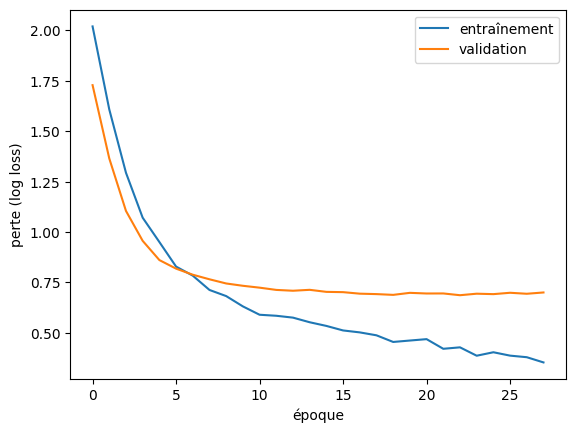

In [40]:
plt.plot(historique.history["loss"], label="entraînement")
plt.plot(historique.history["val_loss"], label="validation")
plt.xlabel("époque"); plt.ylabel("perte (log loss)"); plt.legend(); plt.show()

✅ Arrêt vers la 20e époque. La perte d'entraînement baisse toujours ; celle de validation se stabilise.

### ✏️ Que montrent tes courbes ? Pourquoi l'arrêt précoce s'est-il déclenché ?

*…*

In [41]:
def predict_reseau(E):
    return le.inverse_transform(reseau.predict(E, verbose=0).argmax(axis=1))

print("Keras — F1 macro test :", f1_macro(test["motif"], predict_reseau(E_test)))

Keras — F1 macro test : 0.858


✅ Environ **0,85**.

## Étape 6 — Comparer et conclure

Jusqu'ici, tout a été mesuré sur le **test**, tiré du même corpus que l'entraînement.
Les **avis récents**, eux, ont été écrits par d'autres clients, avec d'autres mots. C'est le moment de vérité.

In [47]:
comparaison = pd.DataFrame([
    {"modèle": "TF-IDF + logreg",
        "F1 test": f1_macro(test["motif"], tfidf.predict(test["texte"])),
        "F1 récents": f1_macro(recents["motif"], tfidf.predict(recents["texte"]))},
    {"modèle": "embeddings + logreg",
        "F1 test": f1_macro(test["motif"], emb_lr.predict(E_test)),
        "F1 récents": f1_macro(recents["motif"], emb_lr.predict(E_recents))},
    {"modèle": "embeddings + Keras",
        "F1 test": f1_macro(test["motif"], predict_reseau(E_test)),
        "F1 récents": f1_macro(recents["motif"], predict_reseau(E_recents))},
])
comparaison

,modèle,F1 test,F1 récents
0,TF-IDF + logreg,0.911,0.389
1,embeddings + logreg,0.861,0.662
2,embeddings + Keras,0.858,0.713


### ✏️ Le classement des modèles est-il le même sur les deux jeux ? Pourquoi, à ton avis ?

*Pense aux limites de TF-IDF vues en cours.*

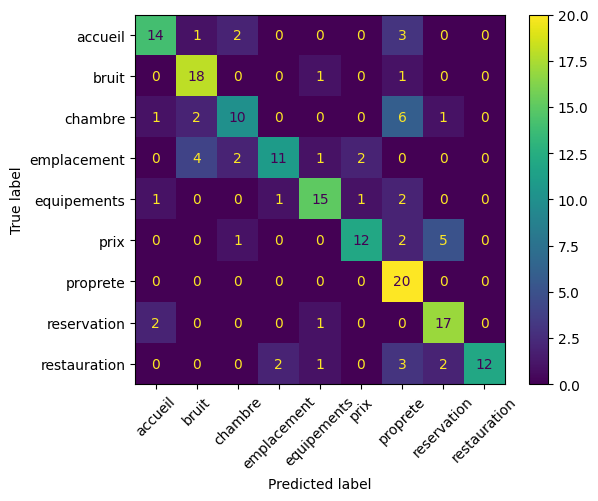

In [48]:
ConfusionMatrixDisplay.from_predictions(recents["motif"], predict_reseau(E_recents), xticks_rotation=45)
plt.show()

### Examiner 10 erreurs

La cellule affiche 10 avis du test où le réseau ne prédit pas l'étiquette du LLM.

In [49]:
erreurs = test.assign(prediction=predict_reseau(E_test)).query("motif != prediction")
print(len(erreurs), "erreurs sur", len(test))
erreurs[["avis_id", "texte", "motif", "prediction"]].head(10)

41 erreurs sur 300


,avis_id,texte,motif,prediction
422,423,"L'emplacement est pourtant idéal. La salle de bain n'avait pas de porte, aucune intimité. À éviter.",restauration,chambre
1170,1171,Lit beaucoup trop petit pour deux adultes. La réceptionniste passait plus de temps sur son téléphone qu'avec les clients. Aucune aide pour monter nos valises alors que nous avions une poussette. L...,chambre,accueil
881,882,"L'accès à l'hôtel est mal indiqué, nous avons tourné une demi-heure. Le minibar est hors de prix. Prix de la chambre doublé par rapport à l'an dernier pour les mêmes prestations. Le supplément vue...",emplacement,prix
388,389,La salle de bain était propre. Le réceptionniste ne nous a même pas regardés.,accueil,reservation
629,630,Séjour professionnel de trois nuits. Une heure d'attente pour être servis au restaurant. Aucun choix pour les végétariens. Une odeur d'égout dans la salle de bain toute la nuit. À éviter.,restauration,proprete
154,155,Le restaurant mérite le détour. Le concierge nous a donné de mauvaises indications et s'en est moqué. Bruit des camions de livraison à 5 h du matin. Les portes claquent dans le couloir toute la nuit.,accueil,bruit
1162,1163,Week-end en couple décevant. La literie était confortable. La carte magnétique se démagnétisait tous les jours. Je déconseille.,equipements,chambre
1103,1104,Avis honnête après 4 nuits : Aucune aide pour monter nos valises alors que nous avions une poussette. Vraiment dommage pour un hôtel si bien noté.,accueil,reservation
866,867,"Vacances en famille, une semaine. Prix d'un quatre étoiles pour une prestation de deux étoiles. Pas assez de rangements, et pas un seul cintre.",chambre,prix
1094,1095,Week-end en couple décevant. Le minibar est hors de prix. Nous avons attendu 40 minutes à la réception sans aucune excuse. Vraiment dommage pour un hôtel si bien noté.,accueil,prix


### ✏️ Pour chaque erreur : le modèle se trompe-t-il, ou l'étiquette du LLM est-elle douteuse ?

| avis_id | texte | motif | prediction | qui a raison |
|---|---|---|---|---|
| 423 | L'emplacement est pourtant idéal. La salle de bain n'avait pas de porte, aucune intimité. À éviter. | restauration | chambre | modèle |
| 1171 | Lit beaucoup trop petit pour deux adultes. La réceptionniste passait plus de temps sur son téléphone qu'avec les clients. Aucune aide pour monter nos valises alors que nous avions une poussette. Le réceptionniste ne nous a même pas regardés. | chambre | accueil | ambiguë |
| 882 | L'accès à l'hôtel est mal indiqué, nous avons tourné une demi-heure. Le minibar est hors de prix. Prix de la chambre doublé par rapport à l'an dernier pour les mêmes prestations. Le supplément vue mer ne valait pas son prix. 2/5 et encore. | emplacement | prix | ambiguë |
| 389 | La salle de bain était propre. Le réceptionniste ne nous a même pas regardés. | accueil | réservation | Avis (LLM) |
| 630 | Séjour professionnel de trois nuits. Une heure d'attente pour être servis au restaurant. Aucun choix pour les végétariens. Une odeur d'égout dans la salle de bain toute la nuit. À éviter. | restauration | propreté | |
| 155 | Le restaurant mérite le détour. Le concierge nous a donné de mauvaises indications et s'en est moqué. Bruit des camions de livraison à 5 h du matin. Les portes claquent dans le couloir toute la nuit. | accueil | bruit | |
| 1163 | Week-end en couple décevant. La literie était confortable. La carte magnétique se démagnétisait tous les jours. Je déconseille. | équipements | chambre | |
| 1104 | Avis honnête après 4 nuits : Aucune aide pour monter nos valises alors que nous avions une poussette. Vraiment dommage pour un hôtel si bien noté. | accueil | réservation | |
| 867 | Vacances en famille, une semaine. Prix d'un quatre étoiles pour une prestation de deux étoiles. Pas assez de rangements, et pas un seul cintre. | chambre | prix | |
| 1095 | Week-end en couple décevant. Le minibar est hors de prix. Nous avons attendu 40 minutes à la réception sans aucune excuse. Vraiment dommage pour un hôtel si bien noté. | accueil | prix | |

## Sauvegarder le modèle retenu

In [46]:
choix = reseau            # ou emb_lr : à toi de choisir, et de le justifier dans la synthèse

MODELS.mkdir(exist_ok=True)
reseau.save(MODELS / "motifs.keras")
(MODELS / "motifs_info.json").write_text(json.dumps({
    "model_name": "motifs",
    "trained_on": date.today().isoformat(),
    "embedding_model": MODEL_NAME,
    "classes": list(le.classes_),   # l'ordre des sorties du réseau : indispensable pour s'en servir / 5
}, indent=2, ensure_ascii=False), encoding="utf-8")
sorted(p.name for p in MODELS.iterdir())

['motifs.keras', 'motifs_info.json']

## ✏️ Synthèse (10 lignes)

- Démarche :
- Comparaison (test et avis récents) :
- Modèle retenu et pourquoi :
- Ce que tu as appris des erreurs :
- Limites :